In [4]:
import os, time, random, json, copy
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Subset, DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [5]:
raw = datasets.EuroSAT(root="data", download=True, transform=transforms.ToTensor())
classes = raw.classes

sp = np.load("splits.npz")
train_idx, val_idx, test_idx = sp["train"], sp["val"], sp["test"]
print(len(train_idx), len(val_idx), len(test_idx))   # ~18900 / 4050 / 4050

18900 4050 4050


In [6]:
loader = DataLoader(Subset(raw, train_idx), batch_size=256, shuffle=False)
n, s, s2 = 0, torch.zeros(3), torch.zeros(3)
for x, _ in loader:
    n += x.numel() / 3
    s += x.sum(dim=[0, 2, 3])
    s2 += (x ** 2).sum(dim=[0, 2, 3])
mean = s / n
std = (s2 / n - mean ** 2).sqrt()
print("mean:", mean, "std:", std)

mean: tensor([0.3439, 0.3800, 0.4075]) std: tensor([0.2024, 0.1367, 0.1154])


In [7]:
norm = transforms.Normalize(mean.tolist(), std.tolist())
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])

train_ds = Subset(datasets.EuroSAT("data", transform=train_tf), train_idx)
val_ds   = Subset(datasets.EuroSAT("data", transform=eval_tf),  val_idx)
test_ds  = Subset(datasets.EuroSAT("data", transform=eval_tf),  test_idx)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

In [8]:
class DSConv(nn.Module):
    """Depthwise 3x3 + pointwise 1x1, each followed by BN + ReLU6."""
    def __init__(self, cin, cout):
        super().__init__()
        self.dw = nn.Conv2d(cin, cin, 3, padding=1, groups=cin, bias=False)
        self.bn1 = nn.BatchNorm2d(cin)
        self.pw = nn.Conv2d(cin, cout, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.act = nn.ReLU6()

    def forward(self, x):
        x = self.act(self.bn1(self.dw(x)))
        return self.act(self.bn2(self.pw(x)))


class ModelB(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU6(),
            nn.MaxPool2d(2),
            DSConv(16, 32),  nn.MaxPool2d(2),
            DSConv(32, 64),  nn.MaxPool2d(2),
            DSConv(64, 128), nn.MaxPool2d(2),
            DSConv(128, 256),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

In [9]:
torch.manual_seed(SEED)
model_b = ModelB().to(device)

total = 0
for name, p in model_b.named_parameters():
    print(f"{name:30s} {p.numel():>8,}")
    total += p.numel()
print("Total trainable:", f"{total:,}")      # expect 50,154
assert total <= 100_000

!pip install -q torchinfo
from torchinfo import summary
summary(model_b, input_size=(1, 3, 64, 64),
        col_names=("output_size", "num_params", "mult_adds"))

features.0.weight                   432
features.1.weight                    16
features.1.bias                      16
features.4.dw.weight                144
features.4.bn1.weight                16
features.4.bn1.bias                  16
features.4.pw.weight                512
features.4.bn2.weight                32
features.4.bn2.bias                  32
features.6.dw.weight                288
features.6.bn1.weight                32
features.6.bn1.bias                  32
features.6.pw.weight              2,048
features.6.bn2.weight                64
features.6.bn2.bias                  64
features.8.dw.weight                576
features.8.bn1.weight                64
features.8.bn1.bias                  64
features.8.pw.weight              8,192
features.8.bn2.weight               128
features.8.bn2.bias                 128
features.10.dw.weight             1,152
features.10.bn1.weight              128
features.10.bn1.bias                128
features.10.pw.weight            32,768


Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
ModelB                                   [1, 10]                   --                        --
├─Sequential: 1-1                        [1, 256, 4, 4]            --                        --
│    └─Conv2d: 2-1                       [1, 16, 64, 64]           432                       1,769,472
│    └─BatchNorm2d: 2-2                  [1, 16, 64, 64]           32                        32
│    └─ReLU6: 2-3                        [1, 16, 64, 64]           --                        --
│    └─MaxPool2d: 2-4                    [1, 16, 32, 32]           --                        --
│    └─DSConv: 2-5                       [1, 32, 32, 32]           --                        --
│    │    └─Conv2d: 3-1                  [1, 16, 32, 32]           144                       147,456
│    │    └─BatchNorm2d: 3-2             [1, 16, 32, 32]           32                        32
│    │    └─ReLU6: 3-

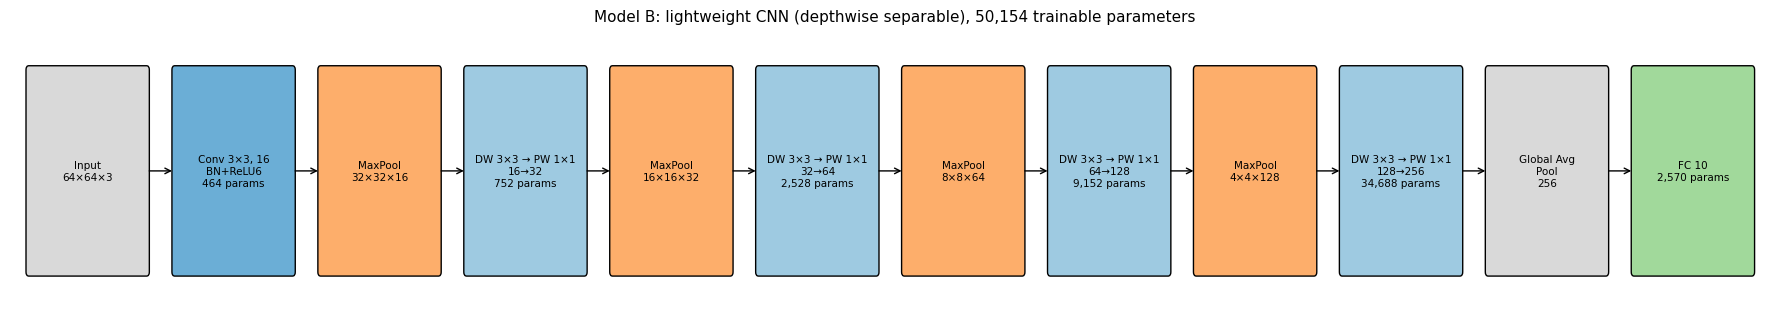

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

C_IN, C_DW, C_PW, C_POOL, C_FC = "#d9d9d9", "#9ecae1", "#6baed6", "#fdae6b", "#a1d99b"

blocks = [
    ("Input\n64×64×3",                       C_IN),
    ("Conv 3×3, 16\nBN+ReLU6\n464 params",   C_PW),
    ("MaxPool\n32×32×16",                    C_POOL),
    ("DW 3×3 → PW 1×1\n16→32\n752 params",   C_DW),
    ("MaxPool\n16×16×32",                    C_POOL),
    ("DW 3×3 → PW 1×1\n32→64\n2,528 params", C_DW),
    ("MaxPool\n8×8×64",                      C_POOL),
    ("DW 3×3 → PW 1×1\n64→128\n9,152 params",C_DW),
    ("MaxPool\n4×4×128",                     C_POOL),
    ("DW 3×3 → PW 1×1\n128→256\n34,688 params", C_DW),
    ("Global Avg\nPool\n256",                C_IN),
    ("FC 10\n2,570 params",                  C_FC),
]

fig, ax = plt.subplots(figsize=(18, 3.2))
w, gap = 1.25, 0.3
for i, (label, color) in enumerate(blocks):
    x = i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 0), w, 1.5, boxstyle="round,pad=0.03",
                                fc=color, ec="black", lw=1))
    ax.text(x + w / 2, 0.75, label, ha="center", va="center", fontsize=7.5)
    if i < len(blocks) - 1:
        ax.annotate("", xy=(x + w + gap, 0.75), xytext=(x + w, 0.75),
                    arrowprops=dict(arrowstyle="->", lw=1))

ax.set_xlim(-0.2, len(blocks) * (w + gap))
ax.set_ylim(-0.2, 1.8)
ax.axis("off")
ax.set_title("Model B: lightweight CNN (depthwise separable), 50,154 trainable parameters", fontsize=11)
plt.tight_layout()
plt.savefig("modelB_architecture.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
import json, copy
import torch.nn.functional as F

criterion = nn.CrossEntropyLoss()   # softmax is built into this loss

def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [12]:
def train_model(model, optimizer, epochs=25, name="model"):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_val_loss, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        run_loss, correct, n = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)

        epoch_time = time.time() - t0          # training time only (excludes validation)
        train_loss, train_acc = run_loss / n, correct / n
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        # keep the weights with the lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(f"[{name}] Epoch {epoch:02d}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.3f} | {epoch_time:.1f}s")

    model.load_state_dict(best_state)          # restore best weights for testing
    with open(f"history_{name}.json", "w") as f:
        json.dump(history, f)
    return history

train model **B**

In [13]:
optimizer = torch.optim.Adam(model_b.parameters(), lr=1e-3)
hist_b = train_model(model_b, optimizer, epochs=25, name="modelB_adam")
print(f"Average time per epoch: {np.mean(hist_b['epoch_time']):.2f}s")

[modelB_adam] Epoch 01/25 | train loss 0.8143 acc 0.718 | val loss 0.5835 acc 0.792 | 11.7s
[modelB_adam] Epoch 02/25 | train loss 0.4984 acc 0.829 | val loss 0.4740 acc 0.834 | 14.7s
[modelB_adam] Epoch 03/25 | train loss 0.4147 acc 0.855 | val loss 0.3992 acc 0.861 | 18.0s
[modelB_adam] Epoch 04/25 | train loss 0.3727 acc 0.868 | val loss 0.3740 acc 0.868 | 23.8s
[modelB_adam] Epoch 05/25 | train loss 0.3307 acc 0.886 | val loss 0.3152 acc 0.888 | 15.9s
[modelB_adam] Epoch 06/25 | train loss 0.3149 acc 0.891 | val loss 0.2951 acc 0.894 | 11.3s
[modelB_adam] Epoch 07/25 | train loss 0.2936 acc 0.896 | val loss 0.2730 acc 0.903 | 11.2s
[modelB_adam] Epoch 08/25 | train loss 0.2748 acc 0.904 | val loss 0.2649 acc 0.907 | 11.9s
[modelB_adam] Epoch 09/25 | train loss 0.2655 acc 0.907 | val loss 0.2638 acc 0.911 | 11.3s
[modelB_adam] Epoch 10/25 | train loss 0.2379 acc 0.915 | val loss 0.2733 acc 0.908 | 11.4s
[modelB_adam] Epoch 11/25 | train loss 0.2499 acc 0.911 | val loss 0.2848 acc 0.

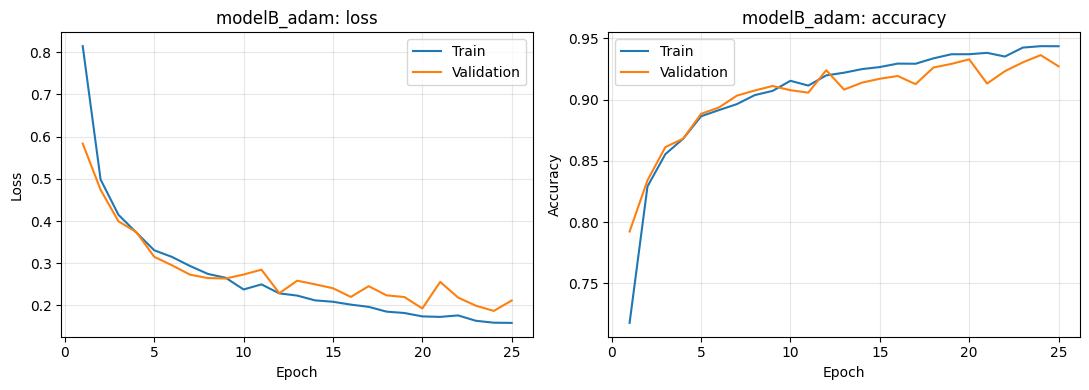

In [14]:
import matplotlib.pyplot as plt

def plot_history(h, title):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h["train_loss"], label="Train")
    ax[0].plot(ep, h["val_loss"], label="Validation")
    ax[0].set(xlabel="Epoch", ylabel="Loss", title=f"{title}: loss")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep, h["train_acc"], label="Train")
    ax[1].plot(ep, h["val_acc"], label="Validation")
    ax[1].set(xlabel="Epoch", ylabel="Accuracy", title=f"{title}: accuracy")
    ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"curves_{title}.png", dpi=150)
    plt.show()

plot_history(hist_b, "modelB_adam")

In [15]:
test_loss, test_acc = evaluate(model_b, test_loader)
print(f"Test loss {test_loss:.4f} | Test accuracy {test_acc:.4f}")

torch.save(model_b.state_dict(), "model_b_adam.pt")
print(f"Model B size: {os.path.getsize('model_b_adam.pt') / 1024:.1f} KB")

Test loss 0.1880 | Test accuracy 0.9370
Model B size: 220.7 KB


Test images: 4,050 | Test accuracy: 93.70%
                      precision    recall  f1-score   support

          AnnualCrop     0.9466    0.9067    0.9262       450
              Forest     0.9845    0.9889    0.9867       450
HerbaceousVegetation     0.8932    0.9111    0.9021       450
             Highway     0.9530    0.8107    0.8761       375
          Industrial     0.9599    0.9573    0.9586       375
             Pasture     0.9349    0.9567    0.9456       300
       PermanentCrop     0.8373    0.9333    0.8827       375
         Residential     0.9955    0.9733    0.9843       450
               River     0.8741    0.9253    0.8990       375
             SeaLake     0.9868    0.9933    0.9900       450

            accuracy                         0.9370      4050
           macro avg     0.9366    0.9357    0.9351      4050
        weighted avg     0.9389    0.9370    0.9370      4050

Macro precision 0.9366 | recall 0.9357 | F1 0.9351


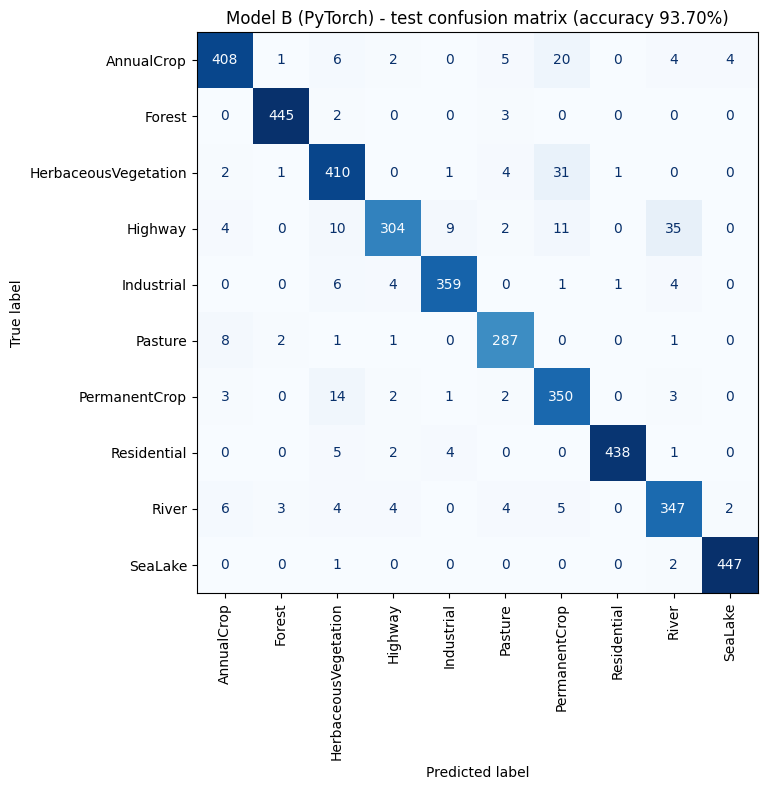

In [16]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_fscore_support)

# 1. Collect predictions on the test set (test_loader has shuffle=False, so order is stable)
model_b.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model_b(x.to(device))
        y_pred.append(out.argmax(1).cpu().numpy())
        y_true.append(y.numpy())
y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)

test_acc = (y_true == y_pred).mean()
print(f"Test images: {len(y_true):,} | Test accuracy: {test_acc:.2%}")   # should match Cell 10

# 2. Per-class and macro precision / recall / F1
print(classification_report(y_true, y_pred, target_names=classes, digits=4))
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Macro precision {p_macro:.4f} | recall {r_macro:.4f} | F1 {f1_macro:.4f}")

# 3. Confusion matrix (rows = true class, columns = predicted class)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, values_format="d", colorbar=False)
ax.set_title(f"Model B (PyTorch) - test confusion matrix (accuracy {test_acc:.2%})")
plt.tight_layout()
plt.savefig("modelB_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# normalized
cm_norm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_norm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, values_format=".2f", colorbar=False)
ax.set_title("Model B (PyTorch) - row-normalized confusion matrix")
plt.tight_layout()
plt.savefig("modelB_confusion_normalized.png", dpi=150, bbox_inches="tight")
plt.show()

# Top confusions, useful for the discussion
pairs = [(cm[i, j], classes[i], classes[j]) for i in range(len(classes))
         for j in range(len(classes)) if i != j and cm[i, j] > 0]
for n, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"{n:4d} images of {t} predicted as {p}")

In [17]:
import json
per_p, per_r, per_f1, sup = precision_recall_fscore_support(y_true, y_pred)
json.dump({
    "model": "Model B (PyTorch)", "test_accuracy": float(test_acc),
    "precision_macro": float(p_macro), "recall_macro": float(r_macro), "f1_macro": float(f1_macro),
    "class_names": list(classes),
    "per_class": {c: {"precision": float(per_p[i]), "recall": float(per_r[i]),
                      "f1": float(per_f1[i]), "support": int(sup[i])} for i, c in enumerate(classes)},
    "confusion_matrix": cm.tolist(),
}, open("results_modelB_pytorch.json", "w"), indent=2)